# Laboratorul 8 — Arbori de decizie
**Student:** Trandafir Florin-Daniel, IASD 2601

Rezolvarea celor șase exerciții, inclusiv vizualizarea opțională.
Clasificăm culoarea vinului și prezicem cantitatea de zahăr rezidual prin regresie.
Rulați celulele în ordine cu **Python 3.11 (local)**, fără mediu virtual.
Fișierul `Wine_Quality_Data.csv` trebuie să fie în același folder cu notebookul.
Biblioteci: NumPy, pandas, Matplotlib, scikit-learn și IPython.

# Obiectivele cursului

- Recunoașteți arborii de decizie și modul în care aceștia pot fi utilizați pentru probleme de clasificare
- Aflați cum se determină cea mai bună divizare și factorii de divizare
- Explicați punctele forte și punctele slabe ale arborilor de decizie
- Explicați modul în care arborii de regresie ajută la clasificarea valorilor continue

## Introducere

Pentru aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține un indicator al calității (3-9, unde valoarea cea mai mare indică o calitate mai bună) și culoarea (roșu sau alb). Numele fișierului este „Wine_Quality_Data.csv”.

**Clarificare:** arborii de regresie prezic valori numerice continue;
arborii de clasificare prezic clase. Pentru vizualizare folosim `plot_tree`
din scikit-learn, astfel încât Graphviz, PyDotPlus și `sklearnex` nu sunt necesare.

In [1]:
%matplotlib inline
from pathlib import Path
from io import StringIO
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, SVG
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold, KFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    mean_squared_error, ConfusionMatrixDisplay,
)
from sklearn.dummy import DummyRegressor

RANDOM_STATE = 42
DATA_PATH = Path('Wine_Quality_Data.csv')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12, 'axes.grid': False})
print('Python:', sys.version.split()[0])
print('Executabil:', sys.executable)
print('scikit-learn:', sklearn.__version__)

Python: 3.14.2
Executabil: /usr/local/bin/python3.14
scikit-learn: 1.9.1


## Întrebarea 1

* Importați datele și studiați funcțiile.
* Le vom folosi pe toate pentru a prezice `color` (alb sau roșu), dar funcția culorilor trebuie codificată ca număr întreg.

In [2]:
data = pd.read_csv(DATA_PATH)
assert set(data['color'].unique()) == {'white', 'red'}
assert not data.isna().any().any(), 'Sunt necesare tratamente pentru valorile lipsă.'
display(data.head())
data.info()
display(data.describe().round(3))

color_mapping = {'white': 0, 'red': 1}
data['color'] = data['color'].map(color_mapping).astype('int64')
X = data.drop(columns='color').copy()
y = data['color'].copy()
assert X.shape[1] == 12 and 'color' not in X.columns
assert X.index.equals(y.index)
display(y.value_counts().rename(index={0: 'alb (0)', 1: 'roșu (1)'}).to_frame('număr'))
print('Forme:', X.shape, y.shape)
print('Rânduri duplicate după prima apariție:', int(data.duplicated().sum()))

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
mean,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818
std,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


,număr
color,
alb (0),4898
roșu (1),1599


Forme: (6497, 12) (6497,)
Rânduri duplicate după prima apariție: 1177


**Interpretare.** `color` este ținta: 0 = alb, 1 = roșu. Celelalte
12 coloane, inclusiv `quality`, sunt caracteristici pentru clasificare.
Arborii împart datele prin comparații cu praguri și nu necesită scalare MinMax
sau standardizare. Păstrăm rândurile originale pentru a respecta exercițiul;
mai jos verificăm explicit posibila suprapunere prin duplicate.

## Întrebarea 2

* Utilizați `StratifiedShuffleSplit` pentru a împărți datele în seturi de trenuri și de teste, stratificate în funcție de calitatea vinului. Dacă este posibil, păstrați indicii privind ponderea pentru întrebarea 5 de mai jos.
* Verificați compoziția procentuală a fiecărui nivel de calitate pentru seturile de date privind trenurile și datele de testare.

,Total (%),Antrenare (%),Test (%),Diferență test-train (pp)
quality,,,,
3,0.462,0.462,0.462,-0.000
4,3.325,3.329,3.308,-0.021
5,32.907,32.904,32.923,0.019
6,43.651,43.660,43.615,-0.044
7,16.608,16.606,16.615,0.010
8,2.971,2.963,3.000,0.037
9,0.077,0.077,0.077,-0.000


Antrenare: 5197 observații; test: 1300 observații.


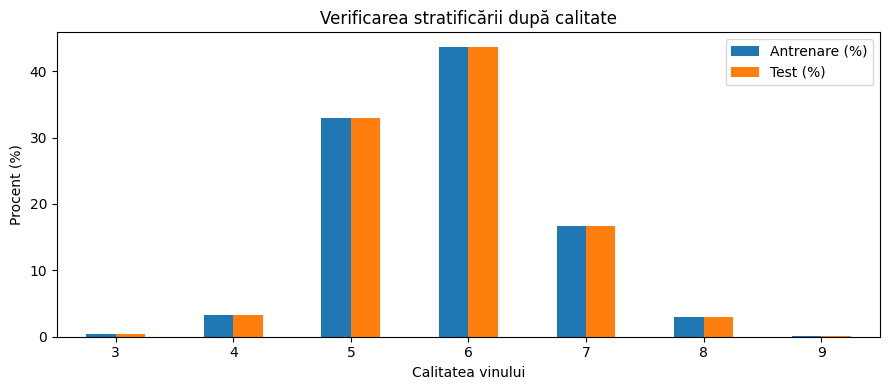

Rânduri de test identice cu cel puțin un rând de antrenare: 357/1300


In [3]:
splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
# Stratificarea este după quality, conform cerinței, nu după ținta color.
train_idx, test_idx = next(splitter.split(X, data['quality']))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
assert set(train_idx).isdisjoint(test_idx)
assert sorted(np.r_[train_idx, test_idx].tolist()) == list(range(len(data)))
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)

quality_percentages = pd.DataFrame({
    'Total (%)': data['quality'].value_counts(normalize=True).mul(100),
    'Antrenare (%)': data.iloc[train_idx]['quality'].value_counts(normalize=True).mul(100),
    'Test (%)': data.iloc[test_idx]['quality'].value_counts(normalize=True).mul(100),
}).sort_index().fillna(0)
quality_percentages['Diferență test-train (pp)'] = (
    quality_percentages['Test (%)'] - quality_percentages['Antrenare (%)'])
display(quality_percentages.round(3))
assert set(data['quality']) == set(data.iloc[train_idx]['quality']) == set(data.iloc[test_idx]['quality'])
print(f'Antrenare: {len(train_idx)} observații; test: {len(test_idx)} observații.')

ax = quality_percentages[['Antrenare (%)', 'Test (%)']].plot.bar(figsize=(9, 4), rot=0)
ax.set(xlabel='Calitatea vinului', ylabel='Procent (%)', title='Verificarea stratificării după calitate')
plt.tight_layout()
plt.show()

row_hashes = pd.util.hash_pandas_object(data, index=False)
duplicate_overlap = row_hashes.iloc[test_idx].isin(row_hashes.iloc[train_idx]).sum()
print(f'Rânduri de test identice cu cel puțin un rând de antrenare: {duplicate_overlap}/{len(test_idx)}')

**Interpretare.** Proporțiile nivelurilor de calitate sunt aproape egale
în antrenare și test; diferențele mici provin din rotunjirea la observații întregi.
Indicii salvați se reutilizează la întrebarea 5, astfel încât ambele probleme
folosesc aceleași observații în cele două subseturi.

**Limită a datelor:** indici diferiți nu garantează observații diferite.
Numărul de rânduri identice raportat mai sus arată că scorurile pot fi optimiste
față de o evaluare pe vinuri complet noi. Pentru acea evaluare, duplicatele ar
trebui eliminate înainte de împărțire sau păstrate în același grup la împărțire
și la validarea încrucișată.

## Întrebarea 3

* Construiți un clasificator pe baza unui arbore de decizie, fără restricții privind adâncimea maximă, numărul de caracteristici sau numărul de frunze.
* Determinați câte noduri sunt prezente în acest arbore (foarte mare) și care este adâncimea acestuia.
* Folosind acest arbore, evaluați eroarea de predicție pe seturile de date de antrenare și de testare. Ce credeți că se întâmplă aici, pe baza diferențelor dintre erorile de predicție?

In [4]:
tree_unrestricted = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_unrestricted.fit(X_train, y_train)

def classification_metrics(model, name):
    rows = []
    for subset, features, target in [
        ('Antrenare', X_train, y_train), ('Test', X_test, y_test),
    ]:
        pred = model.predict(features)
        accuracy = accuracy_score(target, pred)
        rows.append({
            'Model': name, 'Subset': subset, 'Acuratețe': accuracy, 'Eroare': 1 - accuracy,
            'Precizie (roșu)': precision_score(target, pred, zero_division=0),
            'Recall (roșu)': recall_score(target, pred, zero_division=0),
            'F1 (roșu)': f1_score(target, pred, zero_division=0),
        })
    return pd.DataFrame(rows)

unrestricted_metrics = classification_metrics(tree_unrestricted, 'Arbore fără restricții')
print('Noduri:', tree_unrestricted.tree_.node_count)
print('Adâncime:', tree_unrestricted.get_depth())
print('Frunze:', tree_unrestricted.get_n_leaves())
display(unrestricted_metrics.round(4))
error_train, error_test = unrestricted_metrics['Eroare'].to_numpy()
print(f'Diferență eroare test − antrenare: {error_test - error_train:.4f}')

Noduri: 151
Adâncime: 21
Frunze: 76


,Model,Subset,Acuratețe,Eroare,Precizie (roșu),Recall (roșu),F1 (roșu)
0,Arbore fără restricții,Antrenare,0.9996,0.0004,0.9992,0.9992,0.9992
1,Arbore fără restricții,Test,0.9854,0.0146,0.9644,0.9739,0.9691


Diferență eroare test − antrenare: 0.0142


**Interpretare.** Eroarea de clasificare este
$\mathrm{eroare}=1-\mathrm{accuracy}$.
Modelul are `max_depth=None`, `max_features=None`, `max_leaf_nodes=None` și
`ccp_alpha=0`, deci nu impunem limite de complexitate sau tăiere a arborelui.
Divizarea continuă până când frunzele sunt pure sau nu mai există o împărțire
validă. Un scor de antrenare foarte bun și o eroare mai mare pe test indică
supraînvățare; diferența măsurată mai sus arată amploarea ei în această împărțire.
Precizia, recall și F1 sunt calculate pentru clasa pozitivă, vinul roșu.

## Întrebarea 4

* Folosind metoda de căutare în rețea cu validare încrucișată, găsiți un arbore de decizie care să dea rezultate bune pe setul de date de testare. Atribuiți acestui model de arbore de decizie un alt nume de variabilă decât cel din întrebarea 3, astfel încât ambele modele să poată fi utilizate la întrebarea 6.
* Determinați numărul de noduri și adâncimea acestui arbore.
* Calculați erorile pe seturile de date de antrenament și de testare, la fel ca mai devreme, și comparați-le cu erorile arborelui din întrebarea 3.

### Alegerea hiperparametrilor
Folosim 5 folduri stratificate după ținta de clasificare `color`, exclusiv
în setul de antrenare. Stratificarea externă după `quality` rămâne cea cerută
la întrebarea 2. Selectăm modelul după **F1 pentru vinul roșu**, deoarece clasele
sunt dezechilibrate; colectăm și acuratețea și acuratețea echilibrată.
Setul de test nu participă la selectarea parametrilor.

In [5]:
classification_grid = {
    'max_depth': [3, 5, 8, 12, None],
    'min_samples_leaf': [1, 3, 10],
    'max_features': [None, 'sqrt', 0.75],
}
classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
classification_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=classification_grid,
    scoring={'accuracy': 'accuracy', 'f1': 'f1', 'balanced_accuracy': 'balanced_accuracy'},
    refit='f1', cv=classification_cv, n_jobs=1, error_score='raise',
)
classification_search.fit(X_train, y_train)
tree_tuned = classification_search.best_estimator_
assert tree_tuned is not tree_unrestricted
print('Parametri aleși:', classification_search.best_params_)
print(f'F1 mediu în validarea încrucișată: {classification_search.best_score_:.4f}')
classification_cv_results = pd.DataFrame(classification_search.cv_results_)
display(classification_cv_results.sort_values('rank_test_f1')[
    ['params', 'mean_test_f1', 'std_test_f1', 'mean_test_accuracy', 'mean_test_balanced_accuracy']
].head(8))

Parametri aleși: {'max_depth': 8, 'max_features': None, 'min_samples_leaf': 1}
F1 mediu în validarea încrucișată: 0.9700


,params,mean_test_f1,std_test_f1,mean_test_accuracy,mean_test_balanced_accuracy
18,"{'max_depth': 8, 'max_features': None, 'min_sa...",0.969958,0.007011,0.985185,0.977468
27,"{'max_depth': 12, 'max_features': None, 'min_s...",0.969624,0.007114,0.984993,0.977856
37,"{'max_depth': None, 'max_features': None, 'min...",0.969370,0.007061,0.984800,0.978761
19,"{'max_depth': 8, 'max_features': None, 'min_sa...",0.969340,0.007095,0.984800,0.978503
28,"{'max_depth': 12, 'max_features': None, 'min_s...",0.968944,0.008228,0.984608,0.978117
9,"{'max_depth': 5, 'max_features': None, 'min_sa...",0.965472,0.005451,0.983067,0.972699
10,"{'max_depth': 5, 'max_features': None, 'min_sa...",0.964881,0.006002,0.982683,0.973994
24,"{'max_depth': 8, 'max_features': 0.75, 'min_sa...",0.964788,0.007240,0.982683,0.973486


,Model,Subset,Acuratețe,Eroare,Precizie (roșu),Recall (roșu),F1 (roșu)
0,Arbore fără restricții,Antrenare,0.9996,0.0004,0.9992,0.9992,0.9992
1,Arbore fără restricții,Test,0.9854,0.0146,0.9644,0.9739,0.9691
2,Arbore selectat prin CV,Antrenare,0.9948,0.0052,0.9961,0.9830,0.9895
3,Arbore selectat prin CV,Test,0.9854,0.0146,0.9767,0.9608,0.9687


,Model,Noduri,Adâncime,Frunze
0,Fără restricții,151,21,76
1,Selectat prin CV,77,8,39


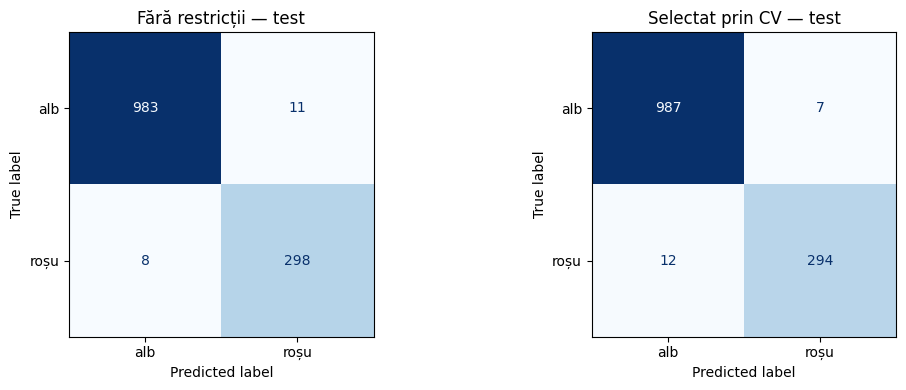

Eroare test inițială: 0.0146; eroare test model CV: 0.0146
Cele două modele au aceeași eroare de test în această împărțire.


In [6]:
tuned_metrics = classification_metrics(tree_tuned, 'Arbore selectat prin CV')
classification_comparison = pd.concat([unrestricted_metrics, tuned_metrics], ignore_index=True)
display(classification_comparison.round(4))
tree_sizes = pd.DataFrame([
    {'Model': name, 'Noduri': model.tree_.node_count,
     'Adâncime': model.get_depth(), 'Frunze': model.get_n_leaves()}
    for name, model in [('Fără restricții', tree_unrestricted), ('Selectat prin CV', tree_tuned)]
])
display(tree_sizes)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, model, title in zip(axes, [tree_unrestricted, tree_tuned], ['Fără restricții', 'Selectat prin CV']):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, labels=[0, 1], display_labels=['alb', 'roșu'],
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title + ' — test')
fig.tight_layout()
plt.show()

old_error = unrestricted_metrics.loc[unrestricted_metrics['Subset'] == 'Test', 'Eroare'].iloc[0]
new_error = tuned_metrics.loc[tuned_metrics['Subset'] == 'Test', 'Eroare'].iloc[0]
print(f'Eroare test inițială: {old_error:.4f}; eroare test model CV: {new_error:.4f}')
if new_error < old_error:
    print('În această împărțire, modelul selectat prin CV reduce eroarea de test.')
elif new_error > old_error:
    print('În această împărțire, modelul selectat prin CV are o eroare de test mai mare.')
else:
    print('Cele două modele au aceeași eroare de test în această împărțire.')

**Interpretare.** `max_depth` limitează lungimea căilor, `min_samples_leaf`
evită frunzele cu prea puține exemple, iar `max_features` limitează numărul
caracteristicilor candidate la fiecare nod. Comparăm numărul de noduri și erorile
din tabel, fără să presupunem că validarea încrucișată garantează o îmbunătățire
pe orice set de test. Alegerea optimizează F1, astfel încât cea mai bună valoare
CV a F1 nu înseamnă obligatoriu cea mai mică eroare de clasificare pe test.

## Întrebarea 5

* Împărțiți din nou datele în părțile `X` și `y`, de data aceasta cu `residual_sugar` ca date de predicție (`y`). *Notă:* dacă indicii au fost salvați din rezultatele `StratifiedShuffleSplit` din întrebarea 2, aceștia pot fi reutilizați pentru împărțirea datelor.
* Folosind căutarea pe grilă cu validare încrucișată, găsiți un model de **regresie** bazat pe un arbore de decizie care să funcționeze bine pe setul de date de testare.
* Evaluați erorile pe seturile de date de antrenare și de testare folosind eroarea medie pătratică.
* Realizați un grafic care să prezinte atât valorile reale, cât și cele previzionate ale zahărului rezidual.

In [7]:
# Datele conțin deja color codificat numeric din întrebarea 1.
X_reg = data.drop(columns='residual_sugar').copy()
y_reg = data['residual_sugar'].copy()
assert 'residual_sugar' not in X_reg.columns and 'color' in X_reg.columns
assert X_reg.shape[1] == 12
X_reg_train, X_reg_test = X_reg.iloc[train_idx].copy(), X_reg.iloc[test_idx].copy()
y_reg_train, y_reg_test = y_reg.iloc[train_idx].copy(), y_reg.iloc[test_idx].copy()
assert X_reg_train.index.equals(X_train.index)
assert X_reg_test.index.equals(X_test.index)
assert X_reg_train.index.equals(y_reg_train.index) and X_reg_test.index.equals(y_reg_test.index)

regression_grid = {
    'max_depth': [4, 6, 10, None],
    'min_samples_leaf': [1, 3, 10],
    'max_features': [None, 'sqrt', 0.75],
}
regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
regression_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=regression_grid, scoring='neg_mean_squared_error',
    cv=regression_cv, refit=True, n_jobs=1, error_score='raise',
)
regression_search.fit(X_reg_train, y_reg_train)
tree_regressor = regression_search.best_estimator_
print('Parametri aleși pentru regresie:', regression_search.best_params_)
print(f'MSE mediu CV: {-regression_search.best_score_:.4f}')
regression_cv_results = pd.DataFrame(regression_search.cv_results_)
best_regression_rows = regression_cv_results.sort_values('rank_test_score').head(8)
display(pd.DataFrame({
    'Parametri': best_regression_rows['params'],
    'MSE mediu CV': -best_regression_rows['mean_test_score'],
    'Deviație standard CV': best_regression_rows['std_test_score'],
}))

Parametri aleși pentru regresie: {'max_depth': None, 'max_features': None, 'min_samples_leaf': 3}
MSE mediu CV: 3.0429


,Parametri,MSE mediu CV,Deviație standard CV
28,"{'max_depth': None, 'max_features': None, 'min...",3.042853,0.559476
19,"{'max_depth': 10, 'max_features': None, 'min_s...",3.196901,0.586876
29,"{'max_depth': None, 'max_features': None, 'min...",3.396418,0.684486
20,"{'max_depth': 10, 'max_features': None, 'min_s...",3.477193,0.698149
25,"{'max_depth': 10, 'max_features': 0.75, 'min_s...",3.799685,0.844091
18,"{'max_depth': 10, 'max_features': None, 'min_s...",3.837960,1.219082
33,"{'max_depth': None, 'max_features': 0.75, 'min...",3.878912,1.098888
27,"{'max_depth': None, 'max_features': None, 'min...",3.896525,1.051549


,Model,Subset,MSE,RMSE
0,Arbore selectat prin CV,Antrenare,0.4828,0.6949
1,Arbore selectat prin CV,Test,2.8504,1.6883
2,Referință: media din train,Antrenare,22.8969,4.7851
3,Referință: media din train,Test,21.5845,4.6459


Noduri regresie: 2847
Adâncime regresie: 24
Frunze regresie: 1424


,Real,Previzionat,Eroare (pred − real)
6400,1.1,1.240,0.140
3310,6.1,7.000,0.900
1483,1.5,1.925,0.425
1492,1.6,1.912,0.312
4841,1.4,1.875,0.475
3928,2.2,2.100,-0.100
5722,3.0,2.300,-0.700
6274,4.5,4.800,0.300
5503,1.9,1.525,-0.375
995,2.0,2.667,0.667


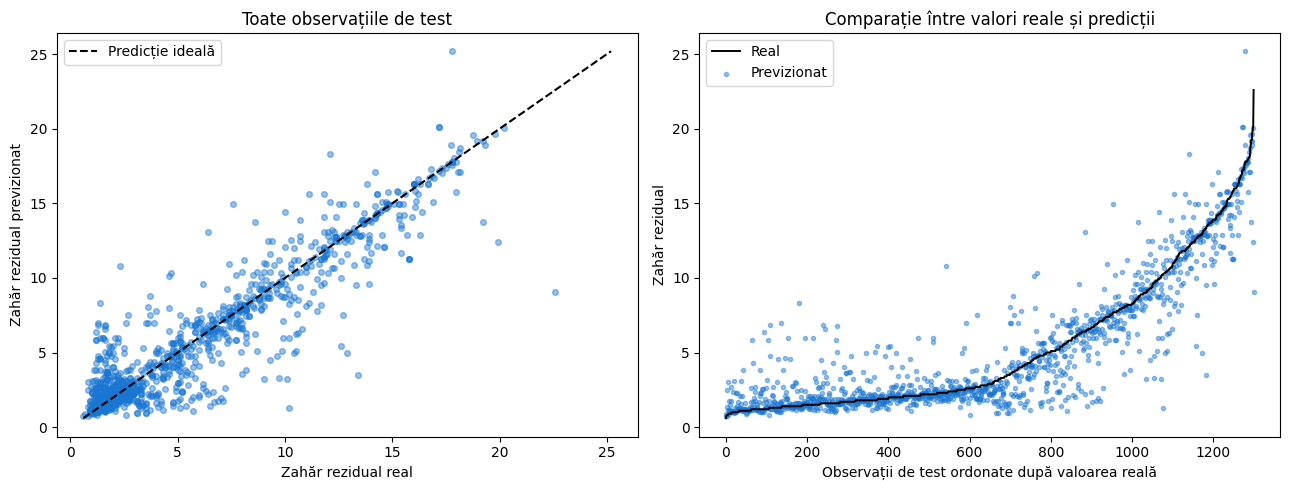

In [8]:
dummy_regressor = DummyRegressor(strategy='mean').fit(X_reg_train, y_reg_train)
regression_rows = []
for name, model in [('Arbore selectat prin CV', tree_regressor), ('Referință: media din train', dummy_regressor)]:
    for subset, features, target in [
        ('Antrenare', X_reg_train, y_reg_train), ('Test', X_reg_test, y_reg_test),
    ]:
        mse = mean_squared_error(target, model.predict(features))
        regression_rows.append({'Model': name, 'Subset': subset, 'MSE': mse, 'RMSE': np.sqrt(mse)})
regression_metrics = pd.DataFrame(regression_rows)
display(regression_metrics.round(4))
print('Noduri regresie:', tree_regressor.tree_.node_count)
print('Adâncime regresie:', tree_regressor.get_depth())
print('Frunze regresie:', tree_regressor.get_n_leaves())

y_reg_pred = tree_regressor.predict(X_reg_test)
predictions = pd.DataFrame({'Real': y_reg_test, 'Previzionat': y_reg_pred})
predictions['Eroare (pred − real)'] = predictions['Previzionat'] - predictions['Real']
display(predictions.head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_reg_test, y_reg_pred, s=17, alpha=0.45, color='#1976d2')
lower = min(y_reg_test.min(), y_reg_pred.min())
upper = max(y_reg_test.max(), y_reg_pred.max())
axes[0].plot([lower, upper], [lower, upper], '--', color='black', label='Predicție ideală')
axes[0].set(xlabel='Zahăr rezidual real', ylabel='Zahăr rezidual previzionat', title='Toate observațiile de test')
axes[0].legend()

ordered = predictions.sort_values('Real')
axes[1].plot(np.arange(len(ordered)), ordered['Real'], label='Real', color='black', linewidth=1.4)
axes[1].scatter(np.arange(len(ordered)), ordered['Previzionat'], label='Previzionat', s=9, alpha=0.45, color='#1976d2')
axes[1].set(xlabel='Observații de test ordonate după valoarea reală', ylabel='Zahăr rezidual',
            title='Comparație între valori reale și predicții')
axes[1].legend()
fig.tight_layout()
plt.show()

**Interpretare.** Eroarea medie pătratică este
$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\widehat y_i)^2$.
GridSearchCV maximizează scorul; de aceea folosim `neg_mean_squared_error`
și inversăm semnul pentru raportarea MSE. RMSE este rădăcina MSE și are aceeași
unitate ca ținta.

În primul grafic, apropierea de diagonala $\widehat y=y$ indică predicții bune.
În al doilea, observațiile sunt sortate după valoarea reală; axa orizontală
nu reprezintă timpul. Abaterile mari contribuie puternic la MSE. Modelul de
referință prezice doar media calculată pe antrenare, oferind un reper simplu.
Arborii de regresie prezic media țintelor din fiecare frunză și nu extrapolează
dincolo de valorile medii învățate.

## Întrebarea 6 *(Opțională)*

Această întrebare este opțională, deoarece pentru rezolvarea ei este necesar un program suplimentar de linie de comandă (GraphViz) și o bibliotecă Python (PyDotPlus). GraphViz poate fi instalat cu ajutorul managerului de pachete pe Linux și Mac. Pentru instalarea bibliotecii PyDotPlus se poate folosi fie `pip`, fie `conda` (`conda install -c conda-forge pydotplus`).

După instalarea acestor programe:

* Creați o vizualizare a arborelui de decizii din întrebarea 3, în care s-a prezis culoarea vinului, iar numărul de caracteristici și/sau diviziuni nu este limitat.
* Creați o vizualizare a arborelui de decizie din întrebarea 4, în care s-a prezis culoarea vinului, dar pentru a găsi adâncimea optimă și numărul optim de caracteristici s-a utilizat căutarea pe grilă.

Arborele de decizie din întrebarea 5 va avea, cel mai probabil, prea multe noduri pentru a putea fi vizualizat.

### Vizualizare fără dependențe suplimentare
Folosim `sklearn.tree.plot_tree` pentru aceiași doi clasificatori păstrați din
întrebările 3 și 4. Mai întâi afișăm primele trei niveluri de divizare pentru
lizibilitate (`(...)` indică ramuri omise). Apoi afișăm **ambii arbori compleți**
în format vectorial SVG, care permite mărirea imaginii fără pierderea clarității.
Trunchierea primei vizualizări nu modifică modelele antrenate.

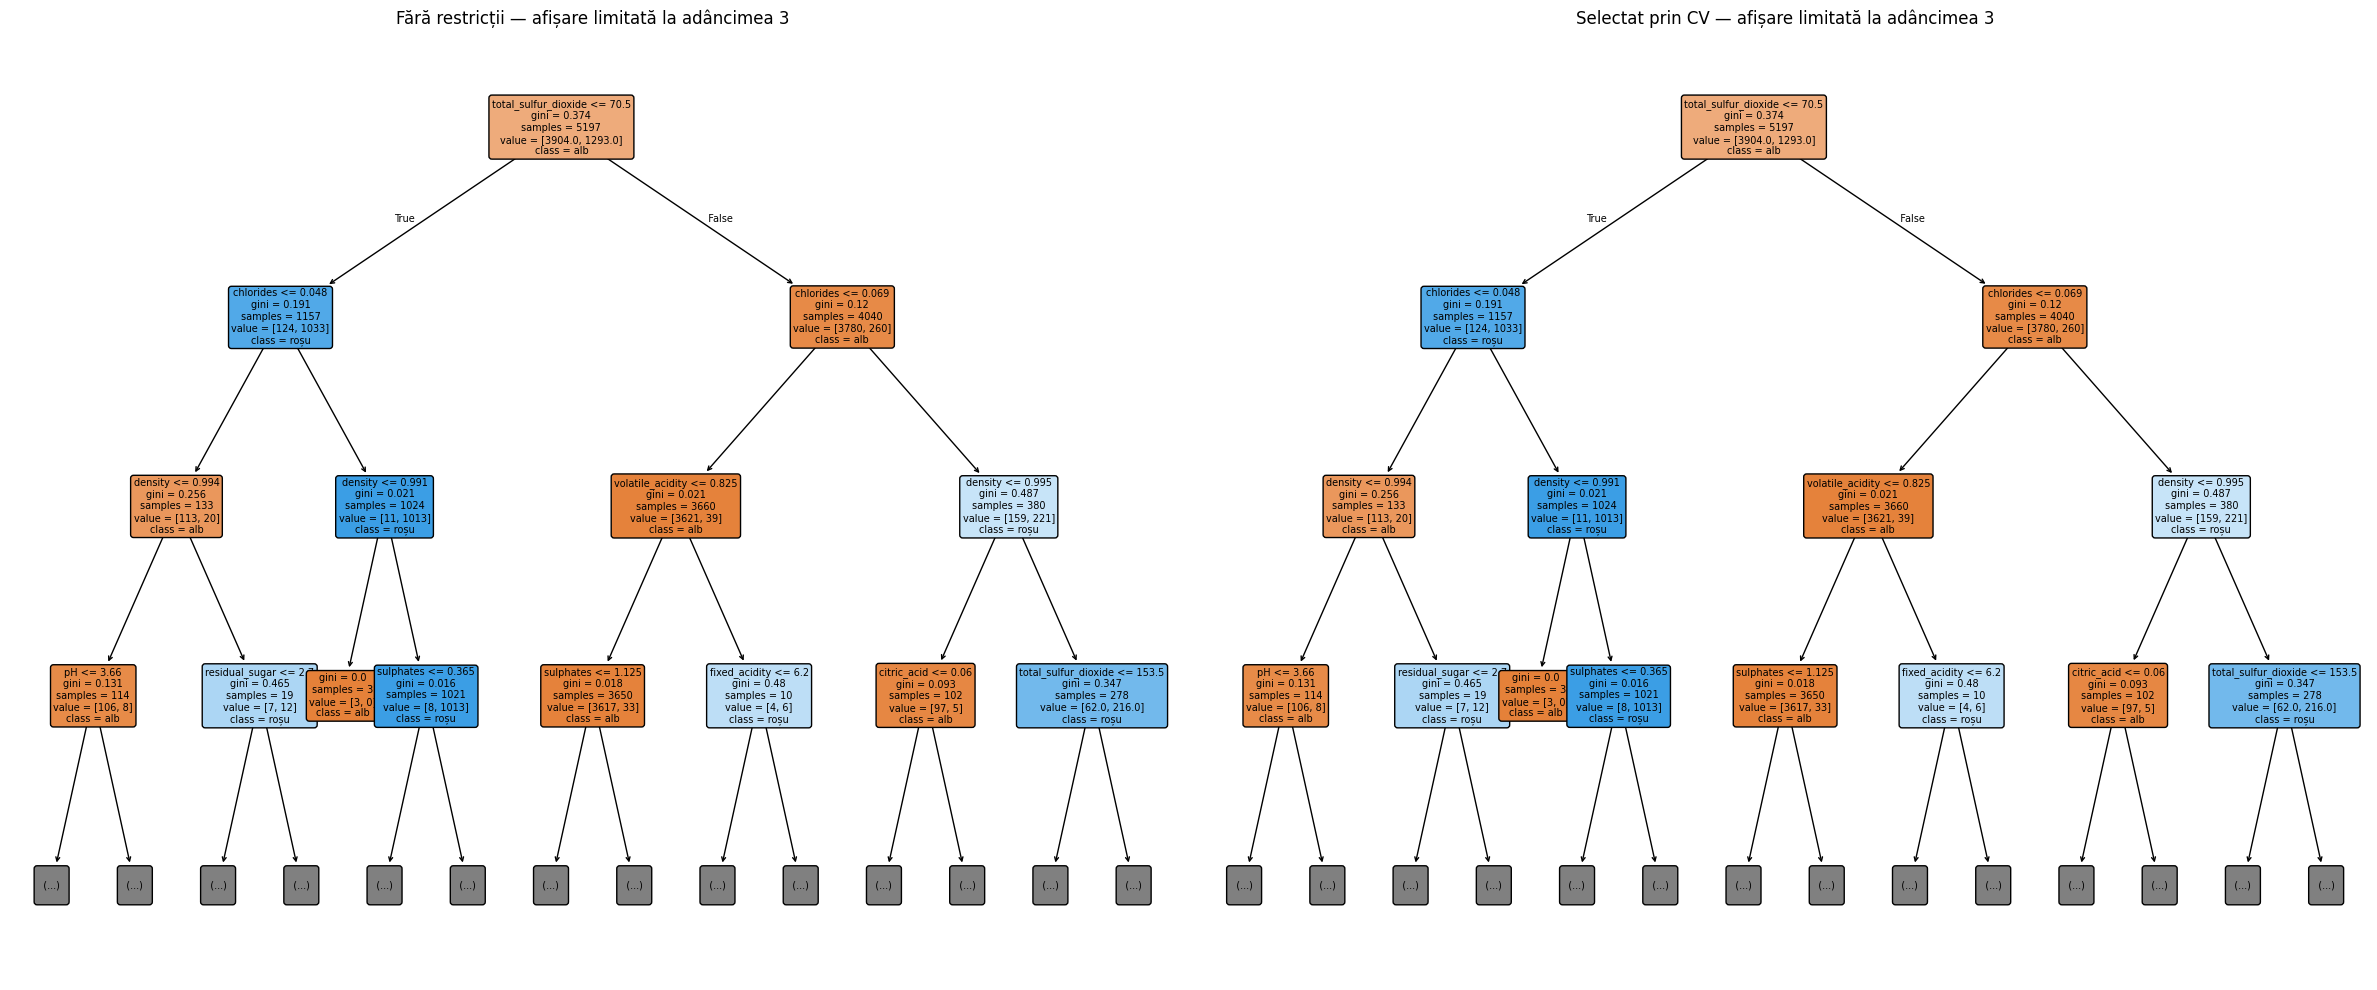

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(24, 10))
for ax, model, title in zip(axes, [tree_unrestricted, tree_tuned], ['Fără restricții', 'Selectat prin CV']):
    plot_tree(model, max_depth=3, feature_names=X.columns.tolist(),
              class_names=['alb', 'roșu'], filled=True, rounded=True,
              impurity=True, precision=3, fontsize=7, ax=ax)
    ax.set_title(title + ' — afișare limitată la adâncimea 3')
fig.tight_layout()
plt.show()

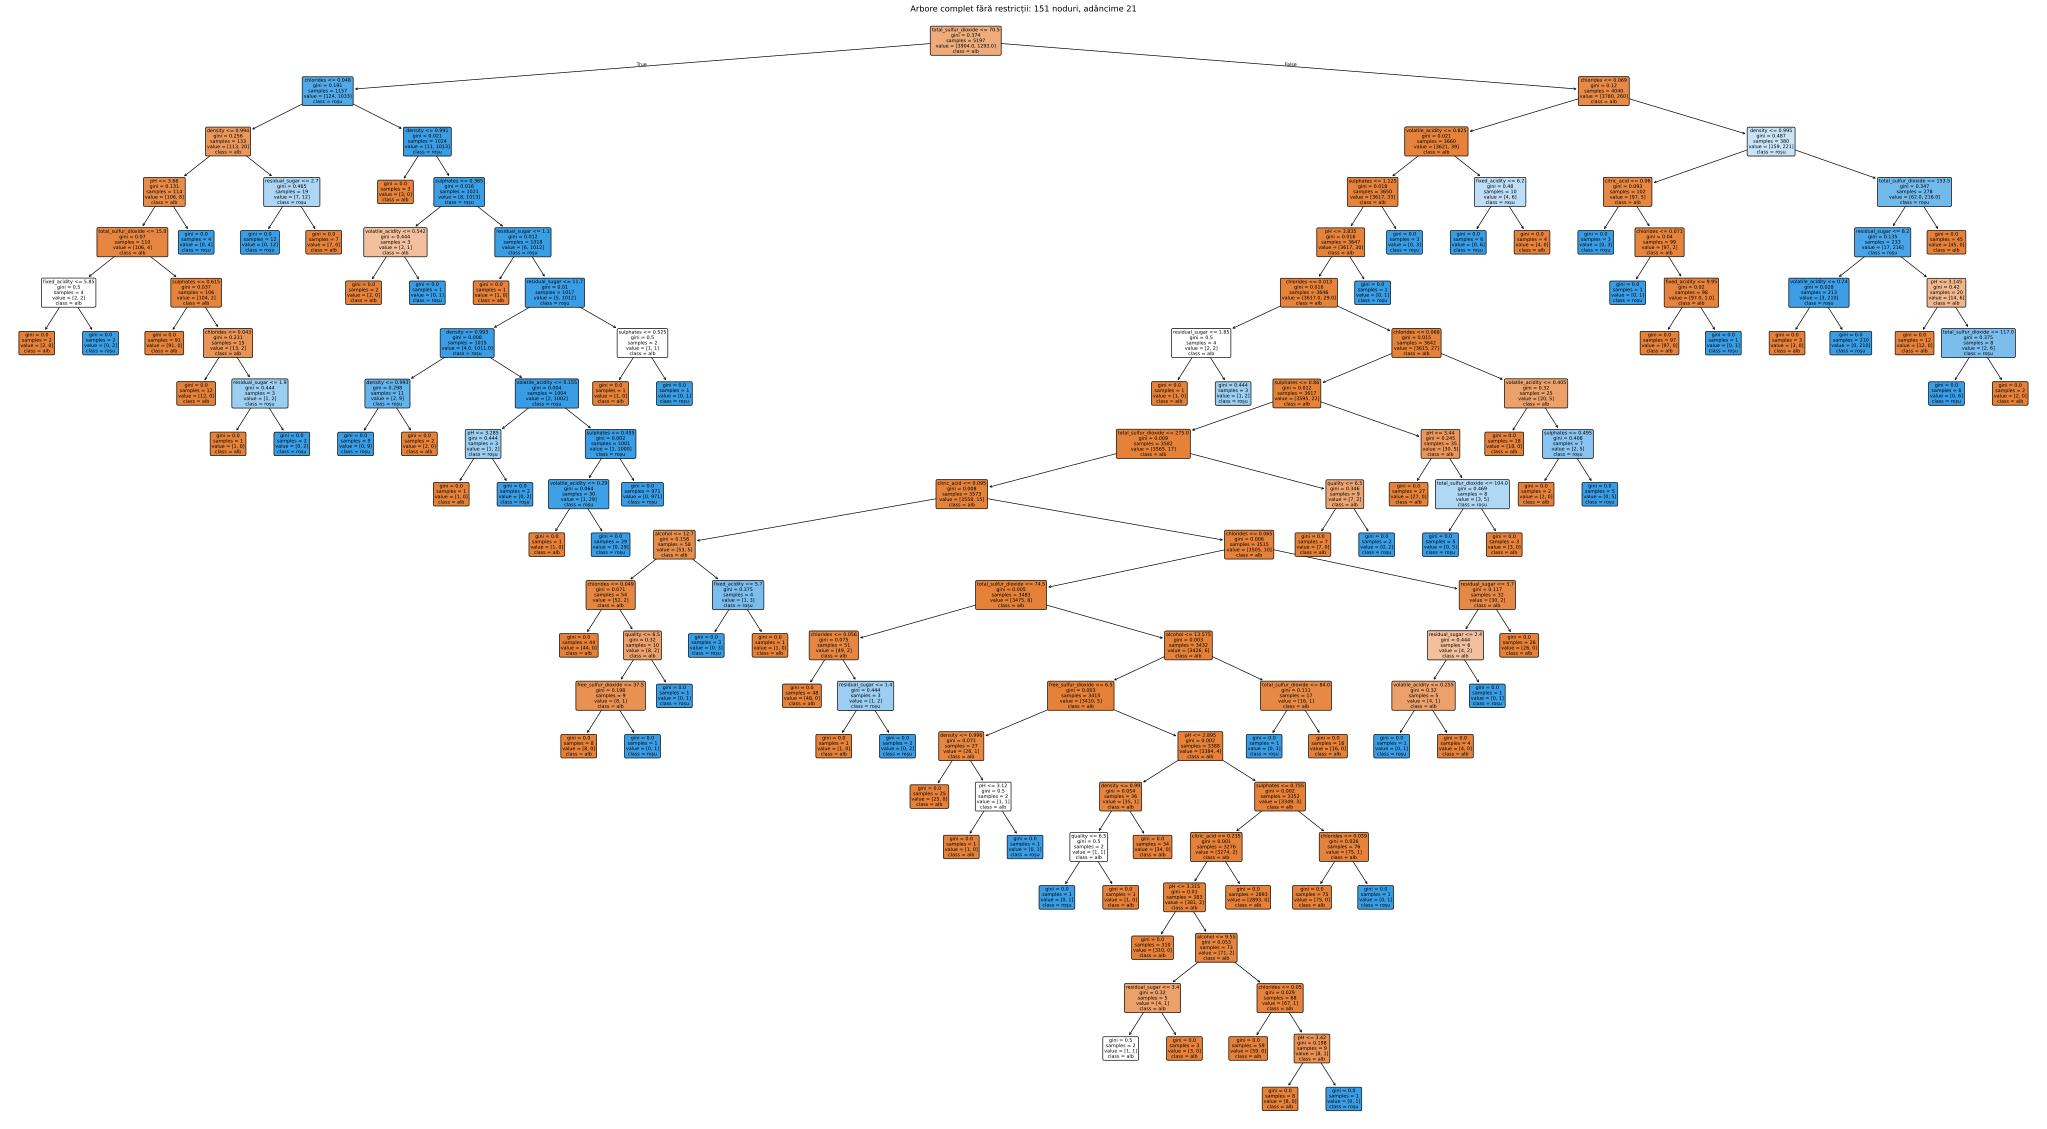

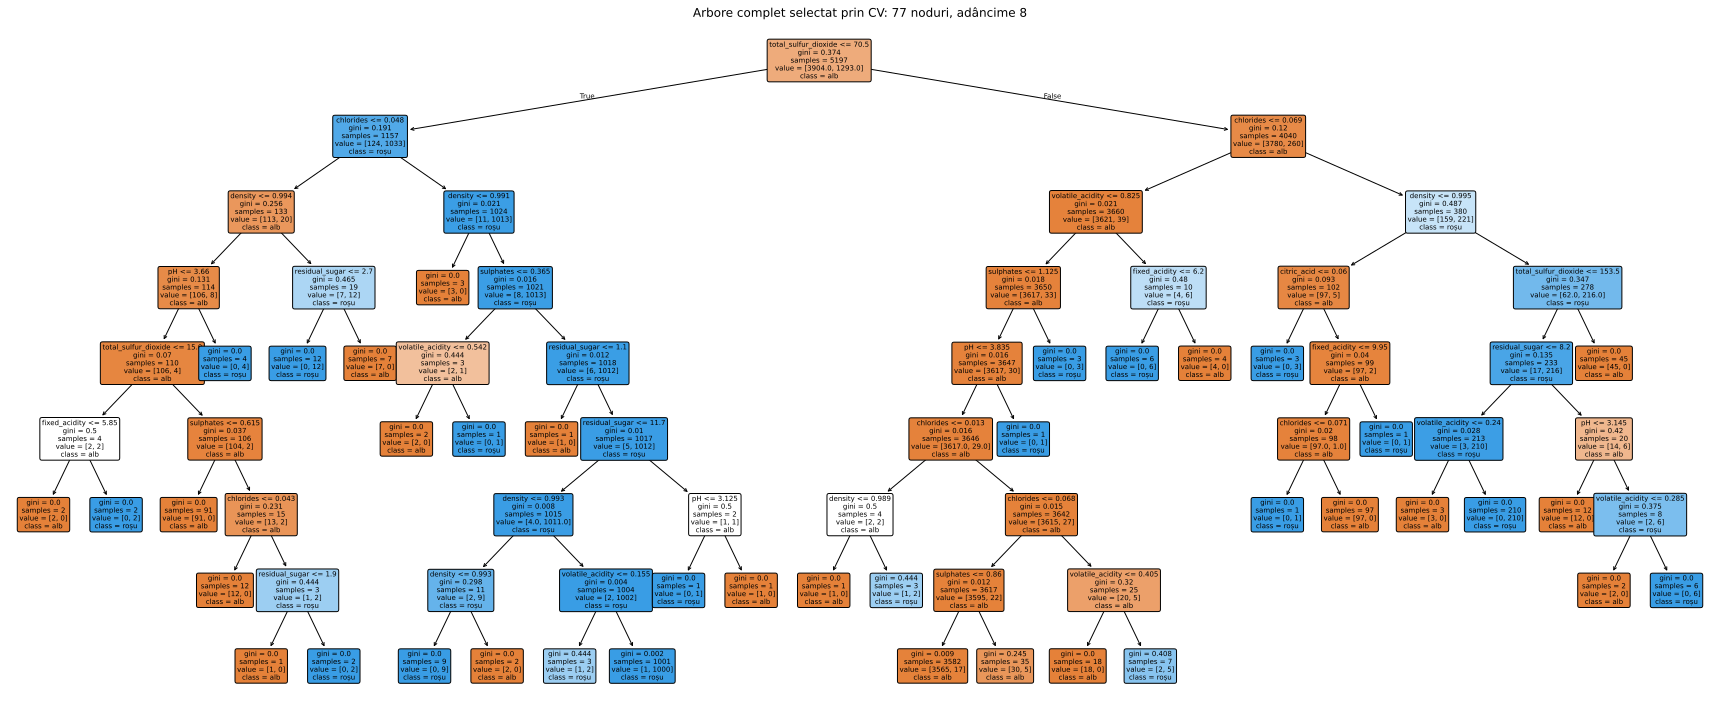

In [10]:
for title, model in [('Arbore complet fără restricții', tree_unrestricted),
                     ('Arbore complet selectat prin CV', tree_tuned)]:
    width = max(24, model.get_n_leaves() * 0.55)
    height = max(10, model.get_depth() * 1.1)
    with plt.rc_context({'svg.fonttype': 'none'}):
        fig, ax = plt.subplots(figsize=(width, height))
        annotations = plot_tree(
            model, feature_names=X.columns.tolist(), class_names=['alb', 'roșu'],
            filled=True, rounded=True, impurity=True, precision=3, fontsize=7, ax=ax)
        # Sunt incluse și etichetele True/False ale ramurilor; numărăm numai nodurile.
        assert sum('samples =' in item.get_text() for item in annotations) == model.tree_.node_count
        ax.set_title(f'{title}: {model.tree_.node_count} noduri, adâncime {model.get_depth()}')
        fig.tight_layout()
        svg_buffer = StringIO()
        fig.savefig(svg_buffer, format='svg', bbox_inches='tight')
        plt.close(fig)
    display(SVG(svg_buffer.getvalue()))

**Citirea unui nod.** Condiția `caracteristică <= prag` trimite observațiile
spre stânga când este adevărată și spre dreapta când este falsă.
`gini` este impuritatea $1-\sum_k p_k^2$; `samples` arată numărul de observații,
`value` numărul de observații din fiecare clasă, în ordinea [alb, roșu],
iar `class` clasa prezisă. Un nod cu `gini=0` este pur.

### Concluzii
- Arborii folosesc reguli explicabile și pot modela relații neliniare fără scalare.
- Un arbore foarte complex poate învăța particularitățile datelor de antrenare.
- Validarea încrucișată alege complexitatea folosind exclusiv datele de antrenare.
- Clasificarea este evaluată prin eroare, acuratețe, precizie, recall și F1; regresia prin MSE și RMSE.
- Arborii sunt sensibili la variații ale eșantionului, iar duplicatele pot face evaluarea prea optimistă.